In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 3.0.3
NumPy version: 2.4.6
Scikit-learn version: 1.9.0


In [2]:
import pandas as pd

data = {
    "study_hours": [2, 5, 1, 6, 3, 7, 2, 4, 8, 3, 5, 1],
    "sleep_hours": [4, 7, 3, 8, 5, 8, 4, 6, 7, 5, 7, 3],
    "heart_rate": [110, 78, 125, 72, 100, 68, 115, 90, 65, 98, 76, 130],
    "exam_stress": [9, 4, 10, 2, 8, 1, 9, 6, 1, 7, 3, 10]
}

df = pd.DataFrame(data)

df["anxiety_level"] = df["exam_stress"].apply(
    lambda x: 1 if x >= 7 else 0
)

df.head()

,study_hours,sleep_hours,heart_rate,exam_stress,anxiety_level
0,2,4,110,9,1
1,5,7,78,4,0
2,1,3,125,10,1
3,6,8,72,2,0
4,3,5,100,8,1


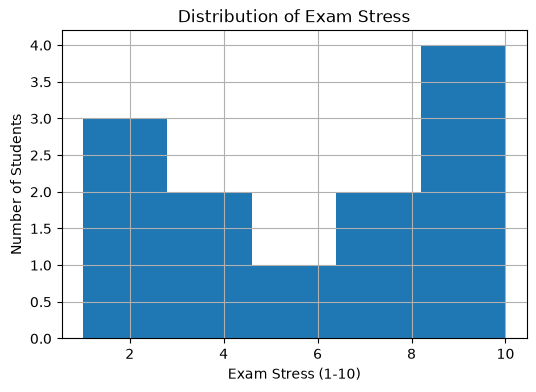

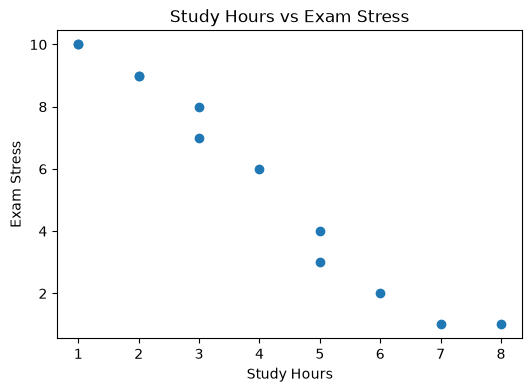

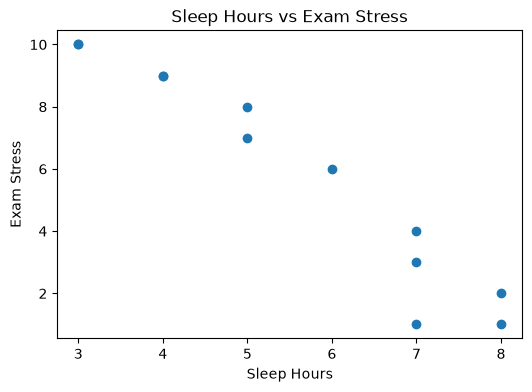

In [3]:
import matplotlib.pyplot as plt

# 1. Exam stress distribution
plt.figure(figsize=(6, 4))
df["exam_stress"].hist(bins=5)
plt.title("Distribution of Exam Stress")
plt.xlabel("Exam Stress (1-10)")
plt.ylabel("Number of Students")
plt.show()

# 2. Study hours vs exam stress
plt.figure(figsize=(6, 4))
plt.scatter(df["study_hours"], df["exam_stress"])
plt.title("Study Hours vs Exam Stress")
plt.xlabel("Study Hours")
plt.ylabel("Exam Stress")
plt.show()

# 3. Sleep hours vs exam stress
plt.figure(figsize=(6, 4))
plt.scatter(df["sleep_hours"], df["exam_stress"])
plt.title("Sleep Hours vs Exam Stress")
plt.xlabel("Sleep Hours")
plt.ylabel("Exam Stress")
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Input features and target
X = df[["study_hours", "sleep_hours",
        "heart_rate", "exam_stress"]]

y = df["anxiety_level"]

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42,
    stratify=y
)

# Train model
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Test accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Model trained successfully!
Test accuracy: 0.6666666666666666
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         2
           1       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3



In [5]:
study = 4
sleep = 5
heart_rate = 100
stress = 8

student = pd.DataFrame([{
    "study_hours": study,
    "sleep_hours": sleep,
    "heart_rate": heart_rate,
    "exam_stress": stress
}])

prediction = model.predict(student)[0]

if prediction == 1:
    print("High exam-stress indicator detected.")
    print("Try a short break and a calm breathing exercise.")
else:
    print("Lower exam-stress indicator detected.")

print("This is a demo prediction, not a medical diagnosis.")

High exam-stress indicator detected.
Try a short break and a calm breathing exercise.
This is a demo prediction, not a medical diagnosis.


In [6]:
import pickle

with open("exam_anxiety_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [7]:
pip install flask

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pickle

with open("exam_anxiety_model.pkl", "rb") as f:
    model = pickle.load(f)

print("Model loaded successfully!")
print("Number of input features:", model.n_features_in_)

Model loaded successfully!
Number of input features: 4
